# EE 447 Final Project Report

<font>*This template is developed by Prof. Sep Makhsous and has been refined with the assistance of Gemini. Graham Rawson has **not** used any generative AI or LLMs in the completion of this document.*</font>

**Student:** <font>*Graham Rawson*</font>

**Selected plant:** <font>*Heavily Modified Plant 7: DC Motor Frequency Control -> Synch. Gen. Freq Control*</font>

**Physical application:** <font >*Synchronous Generator Primary Frequency Control*</font>

All provided headings must be retained.

# Milestone 1 - Student Project Proposal

## 1.1 - Plant Selection and Physical Application

- **Starting Plant Number and Title:**
Plant 7, DC Motor Speed Control
- **Specific Real Device/Process:**
Synchronous Generator Primary Frequency Control System that uses angular frequency, $\omega$, as a state variable along with the generator's electrical output power and mechanical input power from the governor to control the frequency at the power plant's hookup to the electricity grid when sudden disturbances happen that require relatively fast response (seconds to mintues).

#### **Application Narrative and Background:**
*(I'm going over the 150 word limit to explain synchronous generators and frequency control in depth as a background)*<br></br>
 Synchronous Generators are the massive power generators that enable modern society to function. They are called "synchronous" because their mechanical rotational frequency is quite literally tied to the electrical frequency of the power grid, yet they also have control over the power grid's frequency in a complex system of interacitons. Synchronous Generator Primary Frequency Control Loops take local measurements of AC electrical frequency $\omega_e$ at the generator's terminals  and sometimes mechanical frequency $\omega_m$ and feed that back into the governor of the primary energy input systems (usually some variation of a liquid `H2O` or gas `CH4` valve). This governor has a reference angular frequency $\omega_{ref}$ that corresponds to a nominal frequency in Hz $f_{nom}$. A controller attatched to the governor, which for the sake of simplicity, we will simplify to "the governor," uses the variables above to control the power input $P_m$ to the synchronous generator, and thus feedback to the the mechanical/electrical angular frequency $\omega_m$ and $\omega_e$ and the output electrical power $P_e$. An example of this physical system is shown below: <br></br>
 !["Generator Primary Frequency Control System Diagram"](generator_diagram.png)<br></br>
 *Caption: Generator Primary Frequency Control System Diagram*
 <br></br>
 *Source: Power Systems: Fundamental Concepts and the Transition to Sustainability, Daniel S. Kirschen*
 
 This feedback is necessary because the entire state of the power system is never known; generation and loads are constantly varying beyond what we can measure with the current power system's infrastructure. Thus, we cannot have an open-loop control system between the known loads + generation + transmission power and an isolated generator's governor. The unknown exact state of the power system along with uncertainties in inertia, dampening and loss parameters for generators throughout the grid contributes to the error of this technique. Another limitation is that since these isolated generators are not "talking to each other," they cannot coordinate a frequency recovery procedure or solution that could help restore the grid fully back to a quasi-steady state since the total power required to supply the loads on the grid is now different, $P_T$. This is exactly what secondary frequency control does; it dynamically adjusts the setpoints of the generators such that the new power requirements of the grid can be met and the droop characteristic can return to $f_{nom}$ with a new $P_T$. For now, secondary frequency control is currently outside the scope of this modeling project.
 
 However, because the frequency measurement is local, the grid can operate on a basic level over vast distances without requiring a fiber-optic or copper wire communications channel beteween generation sources. This primary frequency control becomes important in case the communications systems were to go down between generation sites, but generally is used in the modern grid to respond to sharp changes in generation, load, or power system topology, such as those due to tranmission faults or mechanical failures of other generators. A graph showing the role of different control systems in frequency maintenance after a large disturbance is below:

 !["Role of Different Control Systems in Frequency Control after a Large Disturbance"](frequency_control.png) <br></br>
 *Source: Power Systems: Fundamental Concepts and the Transition to Sustainability, Daniel S. Kirschen*

## 1.2 - System Boundary and Feedback Signals

The control system uses negative feedback with the error defined as:
$$e(t) = r(t) - y(t)$$

**For my system, I'm choosing to model it based off of a hydropower prime mover and synchronous generator.**<br></br>
Specific Hydroelectric Plant Considerations:

The maximum mechanical output power can be calculated via $P_{hydro} = \eta \rho Q g \Delta h$. $\rho = 1000 kg/m^3$ is the density of water, $Q$ is the flow rate of water in $m^3/s$, the gravitational constant is $g = 9.81 m/s^2$, $\Delta h$ is the effective hydrostatic head in $m$, and $\eta$ is the hydromechanical system's efficiency at converting potential gravitational energy stored in high water to rotational power. Typically, $\eta \approx 90 \%$. 

*(Source: Section 3.4.1 in Power Systems: Fundamental Concepts and the Transition to Sustainability)*
<br></br>


**Define your system signals:**

(Everything below is for my hypothetical system and may not be accurate for all hydroelectric power plants out there):
- $r(t) = \omega_{ref}$: non-time-varying reference of angular frequency of the AC system, `rad/s`, $\omega_{ref} = 2\pi{f_{ref}}$ where $f_{ref} = 60$ Hz, supplied by Grid Operator

- $u(t) = P_m(t)$: output mechanical power, `MW`, limited by $P_m(t) \leq P_{max}$, the maximum mechanical power output of the prime mover. $P_m$ is actuated by the primary energy source governor that takes the required mechanical power and calculates the wicket valve angle to deliver that power.

- $y(t) = \omega_e(t) = \omega_m(t)$: **electrical** angular frequency measurement, `rad/s`, range limited to $0 \leq \omega_e(t) \lessapprox 2.5\omega_{ref}$ runaway frequency dependent on hydro turbine type (<a href="https://www.sciencedirect.com/topics/engineering/runaway-speed">source</a>), measured by generation substation voltage/current transformer and electronic frequency sensor.
If going off of when the frequency relays will trip, $\pm3$ Hz from $\omega_{ref}$ by over/under-frequency transmission relays (<a href="https://www.researchgate.net/figure/Performance-curves-of-frequency-relays-for-delayed-and-instantaneous-operation_fig3_3275422">source</a>). For this model, I'm choosing to go with the 1st limit, because its the actual structural limit of rotational speed for the rotor and prime mover.

- $d(t) = P_e(t) = |\bar{V}(t)||\bar{I}(t)|$: Electric power at the terminals of the generator; the power that the generator supplies is assumed to be equal to the power required by its allocation for the transmission network and the loads, `MW`, expected to be $\approx P_m(t)$ or at least of the same order of magnitude. Might fluctuate in MW at a time. $P_e(t)$'s disturbance comes from changes in generation, loads or topology of the grid.

**Boundary Definitions:**
- **Inside nominal plant boundary:** 
  For $\omega$: Prime Mover, Rotor and Shaft Combined Rotational Inertia $J$, Ball Bearing and other bearing (grease bearing) friction dampening, torsional elastic deformation modeled as a rotational spring
- **Outside nominal plant boundary:** Leakage flux and magnetic decoupling, other magnetic losses such as eddy currents in magnetic materials (generator stator casing, for example), and the power required to run excitation rheostat for active voltage regulation (AVR). I think the most important thing outside the nominal plant boundary is the feedback between the electrical output power and the disturbance, which we are ignoring here.

**Disturbance Justification:**
This disturbance $D(s)$ is injected after the control effect $U(s)$ but before the generator's plant $P(s)$ because the synchronous generator's transfer function requires a power variable to be input, and nowhere else in the diagram is there a power variable. A more satisfying physical explanation would be that the electrical power at the generator's terminals is directly subtracting from the mechanical input power, and any change in load is the thing that might throw this generator into instability. Thus, we can conclude that the location that $P_e(s) = D(s)$ is acting upon is the mechanical power section of the system.

Feedback Block Diagram:
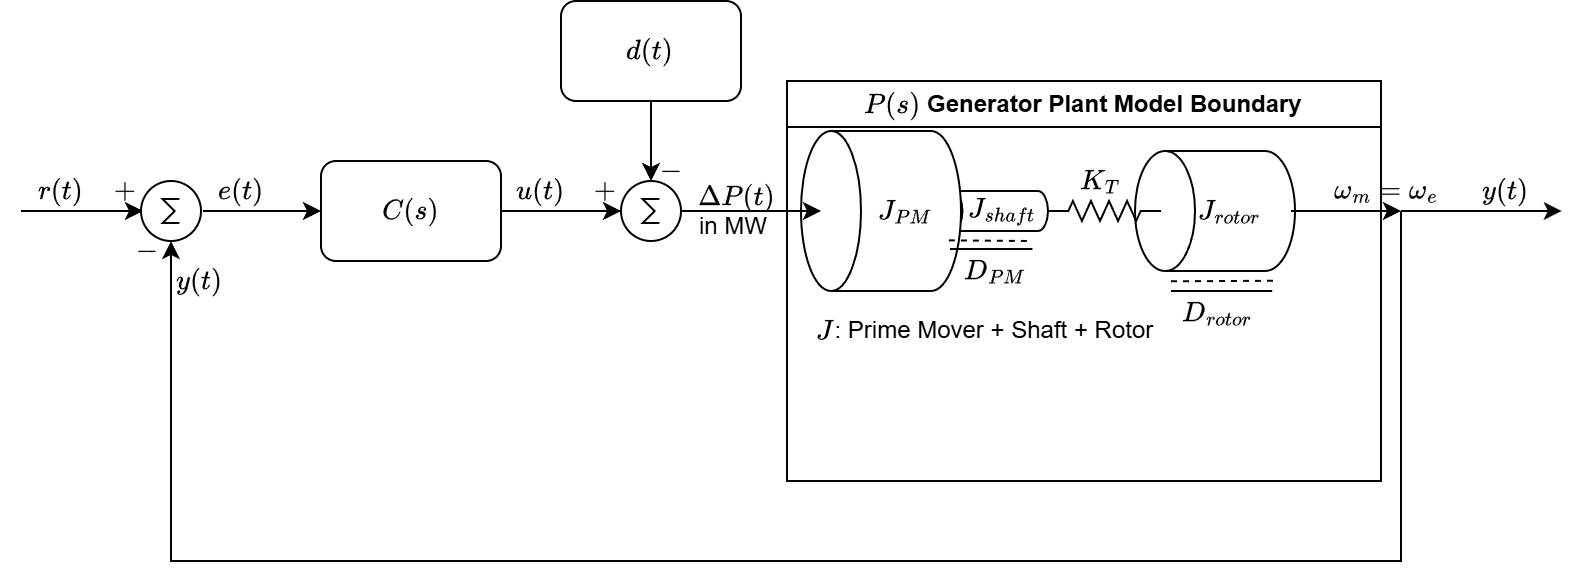

## 1.3 - Preliminary Control Requirements
TODO: *come back later and verify these better*
- **Command test details:** 1MW step in desired output electrical power
- **Maximum 2% settling time ($T_s$):** 30 s
- **Maximum percent overshoot:** 5%
- **Maximum steady-state error ($e_{ss}$):** $0.25$ Hz
- **Maximum actuator effort ($u_{max}$):** 500 MW
- **Disturbance test details:** Disturbance will follow a step input to test the limits of this Primary Frequency Controller in keeping the generator stable. Test will be of 5MW disturbance and be injected after the controller effect U(s). Start time will be t=5s, and the system must recover to within $\pm0.42\%$ of the $f_{nom}$ by 1 minute.

## 1.4 - Parameter Acquisition Plan

| Symbol | Physical meaning | Units | Numerical estimate or exact acquisition method |
|---|---|---:|---|
| [Parameter 1] | [Describe parameter 1] | [Units 1] | [Describe exact acquisition method] |
| [Parameter 2] | [Describe parameter 2] | [Units 2] | [Describe exact acquisition method] |
| [Parameter 3] | [Describe parameter 3] | [Units 3] | [Describe exact acquisition method] |
| [Parameter 4] | [Describe parameter 4] | [Units 4] | [Describe exact acquisition method] |

- **Energy-storage elements:** [Identify the independent energy-storing elements in your system]
- **Nominal plant order:** [Predict whether your nominal model will be 2nd, 3rd, or 4th-order, with a one-sentence justification]

## 1.5 - Personalization and Feasibility

- **Personalization Feature:** [Explain one unique feature making your application different from the standard starting plant]
- **Robustness Parameter:** [Identify one parameter, its nominal value, and planned variation range, e.g., mass +/- 20%]
- **Actuator/Sensor Limitation:** [Identify one physical actuator or sensor limit to check, e.g., saturation, resolution]
- **Scope Statement:** [Briefly explain why the project is SISO, fits a 2nd-4th order model, and is feasible within 10-15 hours]

---

# Milestone 2 - Physical Plant and Mathematical Model

### 2.1 - Physical Schematic, Coordinates, and Assumptions

[Provide a simplified physical schematic of your plant. Define coordinate frames, positive directions, input, output, disturbance, operating point, and a list of explicit physical assumptions.]

### 2.2 - Final Parameter Values

[Present your updated parameter table. Fill in final numerical values, units, sources, calculations, and uncertainty limits where appropriate.]

### 2.3 - Governing Equations

[Write down the force, torque, voltage, or heat balance equations for each independent dynamic element. Show all intermediate steps and make sure relative-motion terms are formulated correctly.]

### 2.4 - Transfer Function and State Space

- **Assumption:** [State the zero-initial-condition assumption used to define the transfer function]
- **Derivation:** [Apply the Laplace transform to your governing equations, show intermediate algebraic steps, and derive the normalized transfer function $P(s) = Y(s)/U(s)$]
- **State Space representation:** [Formulate state space matrices A, B, C, D when appropriate]

### 2.5 - Model Checks

[Check units consistency, signs, polynomial order, pole locations, DC gain behavior, physical limiting cases, and verify that transfer-function poles match state-space eigenvalues where applicable.]

In [2]:
%pip -q install control
import numpy as np
import matplotlib.pyplot as plt
import control as ct


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
# Define the nominal transfer function coefficients
# num = [...]
# den = [...]
# P = ct.tf(num, den)
# print("Nominal Plant P(s) =", P)

---

# Milestone 3 - Analysis, PID Design, Tuning, and Testing

### 3.1 - Open-Loop Plant Analysis

Define the loop transfer function $L(s) = C(s)P(s)H(s)$. For the uncompensated analysis, clearly state the assumed controller or variable gain and use $H(s) = 1$ unless another sensor model is justified.

Calculate the gain margin, phase margin, and root locus using the defined loop transfer function.

[Perform analytical checks and interpret results for poles, zeros, open-loop stability, step response, Bode response, gain/phase margins, and root locus. Provide physical interpretations of your findings.]

In [4]:
# Code for open-loop analysis (poles, zeros, step, Bode, margins, root locus)
# poles = ct.poles(P)
# zeros = ct.zeros(P)
# ...

### 3.2 - Final Control Requirements

[State your final numerical requirements. Justify any updates or adjustments made relative to Milestone 1.]

### 3.3 - Initial Manual PID Design

[Select your controller structure and justify your initial gains using physical control reasoning before moving to numerical search. Discuss controller type, system type, steady-state error, transient targets, stability margins, and control effort. Use the notation $K_P$, $K_I$, and $K_D$ consistently throughout.]

If $K_D$ is nonzero, use a derivative filter or high-frequency regularization pole so the simulated PID controller is proper. State how the filter pole was selected.

In [5]:
# Code for manual PID controller definition and closed-loop step response simulation
# C_manual = ...
# ...

### 3.4 - PID Tuner

[Discuss:
1. Chosen search ranges for $K_P$, $K_I$, and $K_D$
2. Performance metrics and weights
3. Method to reject unstable candidates before scoring
4. Final selected gains from the tuner]

The numerical tuner must refine the initial manual design rather than replace it. Reject unstable candidates before calculating response metrics.

In [6]:
# Code for the PID numerical tuning search algorithm
# ...

### 3.5 - Required Closed-Loop Tests

[Evaluate and compare your system across these 4 tests:
1. Reference tracking
2. Disturbance rejection at the physically justified injection point
3. Robustness to parameter variations
4. Control effort and actuator saturation checks]

Directly compare the uncontrolled or open-loop response, the initial manual controller, and the final tuned controller.

In [7]:
# Code for comparative simulation and plotting
# ...

### 3.6 - Conclusions

State whether each numerical requirement was met. Identify the primary physical limitation, discuss the effect of the robustness variation, and explain what should be improved in a higher-fidelity model or physical implementation.